## Simple Neural Network

- Initialization: The code initializes weights randomly, sets up the input and output datasets, and defines the sigmoid activation function and its derivative.

- Forward Propagation: The input data (a0) is passed through the first layer (with weights w0) using matrix multiplication and the sigmoid activation function. This gives the output of the first layer (a1). The same process is repeated for the second layer (with weights w1) to get the final output (a2).

- Error Calculation: The difference between the predicted output (a2) and the actual output (y) is calculated as the error.

- Back Propagation: The error is propagated back through the network to adjust the weights. The deltas (layer2_delta and layer1_delta) are calculated using the error and the derivative of the sigmoid function.

- Weight Update: The weights (w1 and w0) are updated using the deltas and the outputs of the previous layers. This process is repeated for a specified number of iterations (epochs) to minimize the error.


In [1]:
import numpy as np
import pandas as pd

In [2]:
# Define the sigmoid activation function and its derivative function, to use later.
def sigmoid(x):
  return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
  return x * (1 - x)

In [3]:
# Sample Input dataset
X = np.array([[0,0,1],
              [0,1,1],
              [1,0,1],
              [1,1,1]])

# Sample Output dataset
y = np.array([[0],
              [1],
              [1],
              [0]])

### Prepare Network and Perform Training

Network Structure:
- 3 Input features.
- Layer 1 has 4 Nodes.
- Layer 2 (Output Layer) has 1 Node.


In [4]:
np.random.seed(1)

# Initializing weights randomly, but keeping mean of weights as zero.
w0 = 2 * np.random.random((3,4)) - 1
w1 = 2 * np.random.random((4,1)) - 1

In [7]:
# To collect errors for plotting later
errors = []

# Iterate over 5000 epochs/times (epoch is the mainstream/official term for 1 iteration of forward+backprop)
for i in range(5000):

    

    a0 = X
    a1 = sigmoid(np.dot(a0, w0))
    a2 = sigmoid(np.dot(a1, w1))

    
    # Calculate the error in model output(layer2)

    output_error = y - a2

    # Storing the error for every epoch
    errors.append({
        "epochs": i,
        "error": np.mean(np.abs(output_error))
    })
    # Printing the error every 500 steps
    if (i % 500) == 0:
        print("Error after "+str(i)+" epochs:" + str(np.mean(np.abs(output_error))))
    # Back propagate the error
    layer2_delta = output_error * sigmoid_derivative(a2)
    layer1_error = layer2_delta.dot(w1.T)
    layer1_delta = layer1_error * sigmoid_derivative(a1)

    # Update weights using the layer_delta
    # Hint: a^T * layer_delta

    w1 += a1.T.dot(layer2_delta)
    w0 += a0.T.dot(layer1_delta)

Error after 0 epochs:0.013018434775309309
Error after 500 epochs:0.01227150077483503
Error after 1000 epochs:0.011633855795037219
Error after 1500 epochs:0.011081626203338945
Error after 2000 epochs:0.010597596833851582
Error after 2500 epochs:0.010169010448353064
Error after 3000 epochs:0.009786192568908622
Error after 3500 epochs:0.009441659950134195
Error after 4000 epochs:0.009129524184004874
Error after 4500 epochs:0.008845081777246331


<Axes: xlabel='epochs'>

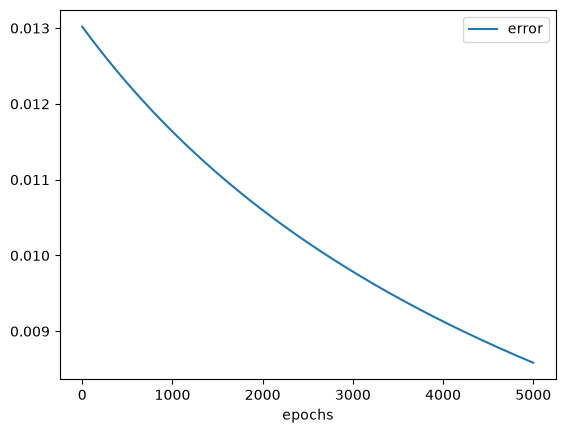

In [8]:
# Plotting Graph of errors vs epochs

pd.DataFrame(errors).plot(x='epochs', y='error')

### Expected Graph

![](https://drive.google.com/uc?export=view&id=1lGSQub9WKVQwGTSUldcnJJ_qwjKtGAy-)